# Reto 1 — Exploración y calidad de datos (EDA)

**Malackathon 2026 · Mercedes-Benz "Clustering the Star"**

Objetivo: describir el dataset de clientes, diagnosticar sus problemas de calidad y proponer un tratamiento justificado. La limpieza efectiva y la selección de features para el modelo se implementan en el Reto 2 (pipeline).

Estructura:
1. Carga, integridad y granularidad
2. Estadísticas descriptivas
3. Valores nulos
4. Inconsistencias, outliers y redundancia
5. Distribuciones de variables clave
6. Exclusión de identificadores y metadatos
7. Resumen y conclusiones

## Resumen

**Qué se hizo:** exploración del fichero (302.850 filas × 38 columnas) para describir a los clientes, detectar los problemas de calidad y decidir cómo tratarlos.

**Resultados clave**
- La granularidad es **cliente–vehículo**: 173.456 clientes y 244.519 vehículos (sección 1).
- **Clientes:** 66 % Suiza y 34 % Austria · 65 % hombres · 61 % con 45 años o más · 73 % con un único vehículo · 71 % nunca ha financiado · ePost autorizado por el 98 % (sección 7).
- **Calidad:** telemetría ~60 % nula y **no aleatoria**; motorización 44 % nula; outliers físicamente dudosos; 5 pares de variables redundantes (ρ ≥ 0,85); ~1.700 posibles flotas (secciones 3–4).

**Decisiones (se aplican en el Reto 2)**
- Agregar a **una fila por cliente**.
- No imputar la telemetría: indicador `has_telemetry` y uso solo para perfilar.
- Completar la motorización a partir del modelo del vehículo.
- Recortar outliers (p1–p99) y aplicar log en lugar de borrar filas; conservar una variable por grupo redundante.

La tabla completa de problemas y tratamientos (Q0–Q13) está en la sección 7.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")

CSV_NAME = "datos_reto_mercedes_benz_malackathon.csv"
# Works whether the kernel starts in notebooks/ (VS Code default) or in the repo root
DATA = next(p for p in (Path(CSV_NAME), Path("..") / CSV_NAME) if p.exists())
EXPECTED_SHA256 = "fb58cecbb924f358967fb5c95259b5f726901b6a0e0a3cc38b849665f48c1dde"

## 1. Carga, integridad y granularidad

La primera descarga del fichero desde Drive llegó **truncada**: faltaba un bloque de 17.925 filas en mitad del archivo y una línea quedó empalmada con 52 campos (rompía `pd.read_csv`). Por eso verificamos la integridad antes de analizar nada: hash SHA-256, índice continuo y número de columnas.

In [2]:
sha = hashlib.sha256(DATA.read_bytes()).hexdigest()
print("SHA-256 correcto:", sha == EXPECTED_SHA256)

# index_col=0: la primera columna es un índice sin nombre
# zipcode como texto: si no, pandas mezcla int y str (4020 vs "4020") y crea falsas inconsistencias
df = pd.read_csv(DATA, index_col=0, dtype={"zipcode": str})
print("Dimensiones:", df.shape)
print("Índice continuo 0..n-1:", (df.index == np.arange(len(df))).all())
df.head(3)

SHA-256 correcto: True


Dimensiones: (302850, 38)
Índice continuo 0..n-1: True


,client_id,vehicle_id,age_range,gender_derived,model_series,vehicle_type,model_class,product_group,engine_concept,country_code,fuel_type,date_of_first_registration,is_current_vehicle,role,role_type,months_as_mb_customer,currently_connected_vehicles,finance_leasing_status,workshop_visits_warranty_goodwill,consent_phone_communication_channel,consent_epost_communication_channel,consent_post_communication_channel,purchasing_power_per_inhabitant_eur,purchasing_power_per_household_eur,population,zipcode,trip_distance_average,trip_distance_mode,trip_distance_median,trip_distance_all_counter,operating_hours_total,fuel_consumption_average,speed_average,speed_mode,speed_median,speed_all_counter,number_of_households,purchasing_power_millions_eur
0,000144e39c02702f821f69beeb7036f40cf8505051050f...,db75a50f450de43f5f7a94d2a05b605fdc1a5d84913ba6...,35-44,female,177,A 180 d,A-Class,P,NaN,AT,NaN,2019-08-06,False,OWNER,B2C,36.00,1,never_active,0,False,True,False,"31,518.15","59,705.40","104,752.00",4020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"55,298.00","3,301.59"
1,000144e39c02702f821f69beeb7036f40cf8505051050f...,e1ddd663e780ffc6dc8194aeb1189a2176ca796d5d3897...,35-44,female,206,C 200 d,C-Class,P,NaN,AT,NaN,2023-09-21,True,OWNER,B2C,36.00,1,never_active,4,False,True,False,"31,518.15","59,705.40","104,752.00",4020,9.59,7.5,7.50,"1,305.00",295.98,6.61,40.34,30,30.00,"1,066,745.60","55,298.00","3,301.59"
2,0002f3a9f4483f444b7665eba96822dad2f1dcfe8d0fab...,716e4f639ce69defa3b9ce202848cdca612814e7d0dc47...,25-34,male,213,AMG E 63 S 4MATIC+,E-Class,P,COMBUSTION,CH,PETROL_PLUS,NaN,True,OWNER,B2C,49.00,1,never_active,0,False,True,True,"34,752.96","81,859.12","6,388.00",9430,NaN,NaN,NaN,NaN,964.89,12.59,NaN,NaN,NaN,NaN,"2,712.00",222.00


In [3]:
g = df.groupby("client_id")
rows_per_client = g.size()
clients_per_vehicle = df.groupby("vehicle_id")["client_id"].nunique()

pd.Series({
    "filas": len(df),
    "clientes únicos": df["client_id"].nunique(),
    "vehículos únicos": df["vehicle_id"].nunique(),
    "filas duplicadas (cliente+vehículo)": df.duplicated(["client_id", "vehicle_id"]).sum(),
    "filas por cliente (media)": rows_per_client.mean(),
    "filas por cliente (máx)": rows_per_client.max(),
    "vehículos con >1 cliente": (clients_per_vehicle > 1).sum(),
}).to_frame("valor")

,valor
filas,"302,850.00"
clientes únicos,"173,456.00"
vehículos únicos,"244,519.00"
filas duplicadas (cliente+vehículo),0.00
filas por cliente (media),1.75
filas por cliente (máx),561.00
vehículos con >1 cliente,"46,648.00"


**Interpretación**

- El fichero verificado está completo: hash correcto, índice continuo y 38 columnas útiles.
- La granularidad es **cliente–vehículo**, no cliente: hay más filas que clientes, y un vehículo puede aparecer con varios clientes (propietario + conductor/usuario).
- Consecuencia para el Reto 2: para segmentar **clientes** hay que agregar a una fila por `client_id`.

## 2. Estadísticas descriptivas

In [4]:
num_cols = df.select_dtypes("number").columns
df[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
model_series,"302,850.00",267.88,150.21,107.00,117.00,177.00,243.00,254.00,907.00,910.00
months_as_mb_customer,"302,846.00",43.87,26.89,0.00,0.00,25.00,39.00,60.00,115.00,120.00
currently_connected_vehicles,"302,850.00",2.15,3.53,0.00,0.00,1.00,1.00,2.00,19.00,21.00
workshop_visits_warranty_goodwill,"302,850.00",1.75,2.43,0.00,0.00,0.00,1.00,3.00,10.00,44.00
purchasing_power_per_inhabitant_eur,"283,763.00","46,481.17","17,294.53","19,701.53","24,291.65","31,518.15","46,165.64","54,210.68","106,183.57","148,353.74"
purchasing_power_per_household_eur,"283,763.00","104,766.27","41,597.55","45,087.34","51,698.89","71,961.82","102,246.51","122,300.85","246,174.02","342,497.95"
population,"283,836.00","19,664.85","36,803.22",0.00,470.00,"3,135.00","7,132.00","17,625.00","220,313.00","220,794.00"
trip_distance_average,"116,993.00",16.16,10.67,1.00,2.84,10.15,14.02,19.53,49.39,300.00
trip_distance_median,"123,020.00",6.62,7.77,1.00,1.00,3.00,7.50,7.50,27.50,300.00
trip_distance_all_counter,"123,020.00","2,351.70","2,768.20",0.00,0.00,518.00,"1,593.00","3,321.00","11,404.62","89,078.00"


In [5]:
cat_cols = ["age_range", "gender_derived", "product_group", "engine_concept", "fuel_type", "country_code",
            "role", "role_type", "finance_leasing_status", "is_current_vehicle",
            "consent_phone_communication_channel", "consent_epost_communication_channel",
            "consent_post_communication_channel"]
cat_summary = pd.concat(
    {c: df[c].value_counts(normalize=True, dropna=False).mul(100).round(1) for c in cat_cols}
).rename("% filas").to_frame()
cat_summary

% filas
age_range                           45-54                   22.50
                                    35-44                   21.30
                                    55-64                   19.60
                                    25-34                   16.70
                                    65+                     16.10
                                    <25                      3.70
gender_derived                      male                    73.70
                                    female                  15.10
                                    NaN                     11.20
product_group                       P                       84.40
                                    T                       13.80
                                    G                        1.40
                                    F                        0.30
engine_concept                      NaN                     44.40
                                    COMBUSTION              32.50
                                    MILD_HYBRID              9.20
                                    PLUGIN_HYBRID            7.00
                                    ELECTRIC                 6.90
fuel_type                           NaN                     59.00
                                    DIESEL                  11.90
                                    PETROL                  10.70
                                    ELECTRIC                 6.90
                                    PETROL_PLUS              4.60
                                    DIESEL,ELECTRIC          2.80
                                    PETROL,ELECTRIC          2.40
                                    PETROL_PLUS,ELECTRIC     1.60
country_code                        CH                      63.70
                                    AT                      36.30
role                                OWNER                   87.30
                                    USER                     5.80
                                    LEGACY                   3.70
                                    DRIVER                   1.80
                                    TEMP_USER                1.30
role_type                           B2C                     98.20
                                    B2B                      1.80
finance_leasing_status              never_active            58.30
                                    active_FL_only          22.00
                                    active_FL_and_CASH      10.30
                                    was_active               9.40
is_current_vehicle                  True                    59.50
                                    False                   40.50
consent_phone_communication_channel True                    85.60
                                    False                   14.40
consent_epost_communication_channel True                    98.30
                                    False                    1.70
consent_post_communication_channel  True                    85.10
                                    False                   14.90

In [6]:
df.nunique().sort_values(ascending=False).to_frame("valores distintos")

,valores distintos
vehicle_id,244519
client_id,173456
speed_all_counter,117441
operating_hours_total,80976
trip_distance_all_counter,10780
speed_average,8248
trip_distance_average,5476
date_of_first_registration,5316
purchasing_power_per_household_eur,5035
purchasing_power_per_inhabitant_eur,5032


**Interpretación**

- Las variables de telemetría y de conteo (`speed_all_counter`, `trip_distance_all_counter`, `operating_hours_total`) tienen colas muy largas: el p99 está muy por debajo del máximo.
- `vehicle_type` tiene más de 1.400 valores distintos y `model_series` es un código numérico, no una magnitud: ninguna de las dos se puede usar tal cual.
- `consent_epost_communication_channel` es True en casi todas las filas: apenas discrimina entre clientes.

## 3. Valores nulos

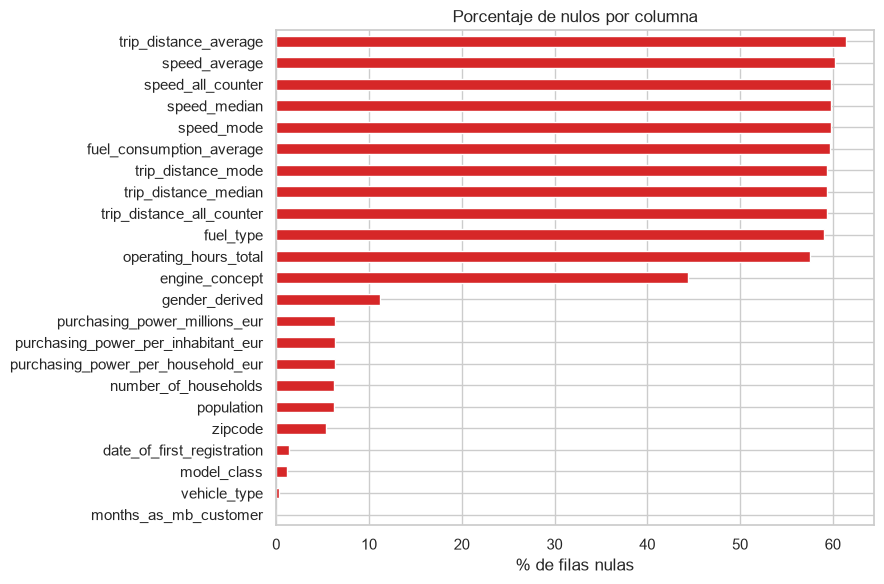

,% nulos
trip_distance_average,61.40
speed_average,60.20
speed_all_counter,59.80
speed_median,59.80
speed_mode,59.80
fuel_consumption_average,59.70
trip_distance_mode,59.40
trip_distance_median,59.40
trip_distance_all_counter,59.40
fuel_type,59.00


In [7]:
nulls = df.isna().mean().mul(100).sort_values(ascending=False)
nulls = nulls[nulls > 0]

fig, ax = plt.subplots(figsize=(9, 6))
nulls.plot.barh(ax=ax, color="tab:red")
ax.invert_yaxis()
ax.set_xlabel("% de filas nulas")
ax.set_title("Porcentaje de nulos por columna")
plt.tight_layout()
plt.show()
nulls.round(1).to_frame("% nulos")

In [8]:
tele = ["trip_distance_average", "operating_hours_total", "speed_average", "fuel_consumption_average"]
print("Filas sin ningún dato de telemetría: {:.1f} %".format(df[tele].isna().all(axis=1).mean() * 100))
df.groupby("is_current_vehicle")[tele].apply(lambda x: x.isna().mean().mul(100)).round(1)

Filas sin ningún dato de telemetría: 52.2 %


,trip_distance_average,operating_hours_total,speed_average,fuel_consumption_average
is_current_vehicle,,,,
False,74.30,70.80,72.80,72.30
True,52.60,48.50,51.60,51.10


**Interpretación**

- **Telemetría (~60 % nulos):** falta en bloque (todas las métricas a la vez) y es más frecuente en vehículos que ya no son actuales. No es un nulo aleatorio: indica que el vehículo **no está conectado**. Imputar el 60 % de los valores inventaría la mayor parte de la columna (apuntes: eliminar o no imputar atributos mayoritariamente vacíos). Propuesta: crear el flag `has_telemetry` y agregar la telemetría por cliente; imputar con mediana solo si se usa en el modelo.
- **`fuel_type` (~59 %) y `engine_concept` (~44 %):** cuando falta `engine_concept` también falta siempre `fuel_type` (sección 4.1), así que uno no sirve para completar el otro; la motorización se completará desde el modelo del vehículo en el Reto 2.
- **`gender_derived` (~11 %):** además es un dato *inferido*, no declarado. Se mantiene la categoría `unknown` y se usa solo para perfilar.
- **Socioeconómicas (~6 %) y `zipcode` (~5 %):** imputación con la mediana por país.
- **`date_of_first_registration` (~1,4 %) y `model_class` (~1 %):** porcentaje bajo; imputación por `model_series` (mediana de fecha / clase más frecuente).

### Propuesta de tratamiento de nulos

Criterios aplicados (apuntes de preprocesado):

- **Eliminar filas** solo si afectan a menos del 5 % y los huecos son aleatorios; si no, se pierde poder estadístico y se sesga el modelo hacia un subgrupo.
- **No imputar columnas mayoritariamente vacías**: rellenarlas inventaría la mayor parte de los datos y añadiría más ruido que información.
- **Mediana** para numéricas (más robusta que la media ante las colas largas vistas en la sección 2) y **moda o categoría explícita** para categóricas.

| Columnas | % nulos | ¿Aleatorio? | Tratamiento | Justificación |
|---|---|---|---|---|
| Telemetría: `trip_distance_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average` | 58–61 % | **No**: falta en bloque y más en vehículos no actuales (74 % vs 53 %) | Crear `has_telemetry` (1 si el cliente tiene algún vehículo con datos) y agregar las métricas por cliente. Solo si se incluyen en el modelo: imputar con la mediana **después** de agregar | El nulo significa "vehículo no conectado": es información en sí. Imputar el ~60 % inventaría la mayoría de la columna |
| `fuel_type` | 59 % | No (mismo patrón que `engine_concept`) | No se usa como feature | Redundante con `engine_concept` y nulo siempre que este lo es (crosstab 4.1) |
| `engine_concept` | 44 % | No | Completar desde el modelo del vehículo (`vehicle_type`), en el Reto 2; lo que no se pueda recuperar se imputa a nivel cliente | `fuel_type` no ayuda: es nulo en las mismas filas. El modelo del vehículo determina su motorización |
| `gender_derived` | 11 % | Desconocido | Categoría `unknown`; usar solo para perfilar segmentos, no para entrenar | Es un dato inferido, no declarado: imputarlo sería inferir sobre una inferencia |
| Socioeconómicas: `purchasing_power_*`, `population`, `number_of_households` | 6,3 % | Ligado a zonas sin dato | `population = 0` → nulo; imputar con la **mediana por país** | Cerca del umbral del 5 %; eliminar perdería ~19.000 filas. Por país porque la distribución es bimodal CH/AT (sección 5) |
| `zipcode` | 5,3 % | — | Sin tratamiento | Se excluye por ser identificador (sección 6) |
| `date_of_first_registration` | 1,4 % | Sí (bajo) | Imputar la feature derivada `vehicle_age` con la mediana por `model_series` | < 5 %; el modelo de la serie es el mejor indicador de la antigüedad |
| `model_class` | 1,1 % | Sí (bajo) | Moda por `model_series` | < 5 %; la serie determina la clase |
| `vehicle_type` | 0,3 % | Sí | Sin tratamiento | No se usa como feature (1.436 categorías) |
| `months_as_mb_customer` | < 0,01 % (4 filas, 2 clientes) | Sí | Eliminar esas filas | Impacto despreciable y sin sesgo |

La imputación se implementa dentro del **pipeline del Reto 2**, para que se ajuste solo con los datos de entrenamiento y sea reproducible.

## 4. Inconsistencias, outliers y redundancia

### 4.1 Coherencia entre motorización y combustible

In [9]:
pd.crosstab(df["engine_concept"].fillna("NULO"), df["fuel_type"].fillna("NULO"))

fuel_type,DIESEL,"DIESEL,ELECTRIC",ELECTRIC,NULO,PETROL,"PETROL,ELECTRIC",PETROL_PLUS,"PETROL_PLUS,ELECTRIC"
engine_concept,,,,,,,,
COMBUSTION,28475,0,0,43915,14422,0,11612,0
ELECTRIC,0,0,20944,0,0,0,0,0
MILD_HYBRID,7418,0,0,29,17946,0,2362,0
NULO,0,0,0,134390,0,0,0,0
PLUGIN_HYBRID,0,8604,0,411,0,7371,0,4951


### 4.2 Columnas de texto con listas de intervalos

In [10]:
for c in ["trip_distance_mode", "speed_mode"]:
    has_list = df[c].str.contains(",", na=False)
    print(f"{c}: {has_list.sum():,} filas con listas de intervalos")
    print("  ejemplos:", df.loc[has_list, c].unique()[:3].tolist())

trip_distance_mode: 7,049 filas con listas de intervalos
  ejemplos: ['3,7.5', '1,3,7.5,15,27.5,42.5,62.5,87.5,150,300', '2.5,7.5,15,30,60,100,180']
speed_mode: 1,223 filas con listas de intervalos
  ejemplos: ['0.125,10.0625,30,50,75,110,165,220', '0.125,15.0625,45,75,110,150,205,264', '0.125,10.0625,40,75,110,165,225,275']


### 4.3 Outliers (criterios IQR y Z-score)

In [11]:
out_cols = ["months_as_mb_customer", "currently_connected_vehicles", "workshop_visits_warranty_goodwill",
            "purchasing_power_per_household_eur", "population", "trip_distance_average",
            "operating_hours_total", "fuel_consumption_average", "speed_average", "speed_all_counter"]

def outlier_summary(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    return pd.Series({
        "% fuera IQR": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100,
        "% |z|>3": (z.abs() > 3).mean() * 100,
        "p99": s.quantile(.99),
        "máx": s.max(),
    })

df[out_cols].apply(outlier_summary).T

,% fuera IQR,% |z|>3,p99,máx
months_as_mb_customer,1.50,0.00,115.00,120.00
currently_connected_vehicles,11.03,4.34,19.00,21.00
workshop_visits_warranty_goodwill,3.39,1.45,10.00,44.00
purchasing_power_per_household_eur,3.59,2.09,"246,174.02","342,497.95"
population,9.76,3.03,"220,313.00","220,794.00"
trip_distance_average,4.67,1.12,49.39,300.00
operating_hours_total,4.64,1.56,"3,393.64","26,842.00"
fuel_consumption_average,3.75,1.18,19.00,50.00
speed_average,3.74,1.88,80.45,220.00
speed_all_counter,4.64,0.18,"13,326,747.63","1,452,478,022.80"


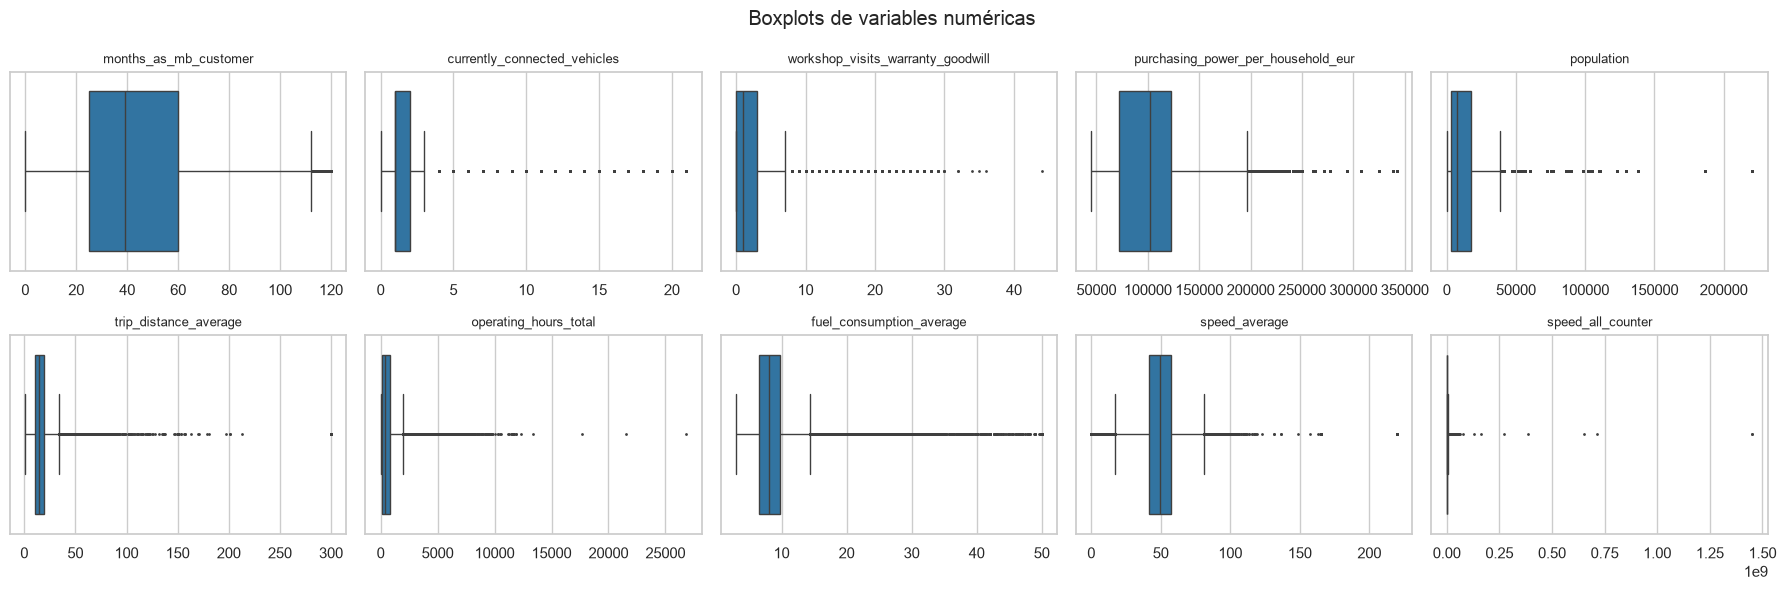

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, c in zip(axes.flat, out_cols):
    sns.boxplot(x=df[c], ax=ax, color="tab:blue", fliersize=1)
    ax.set_title(c, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Boxplots de variables numéricas")
plt.tight_layout()
plt.show()

In [13]:
reg = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
current_per_client = g["is_current_vehicle"].sum()
pd.Series({
    "speed_average > 150 km/h": (df["speed_average"] > 150).sum(),
    "fuel_consumption_average > 25": (df["fuel_consumption_average"] > 25).sum(),
    "consumo informado en eléctricos": df.loc[df["engine_concept"] == "ELECTRIC", "fuel_consumption_average"].notna().sum(),
    "population = 0": (df["population"] == 0).sum(),
    "months_as_mb_customer = 0": (df["months_as_mb_customer"] == 0).sum(),
    "fechas no parseables": reg.isna().sum() - df["date_of_first_registration"].isna().sum(),
    "fecha mínima": reg.min().date(),
    "fecha máxima": reg.max().date(),
    "clientes con >10 vehículos": (rows_per_client > 10).sum(),
    "% coincidencia vehículos actuales vs currently_connected_vehicles":
        round((current_per_client == g["currently_connected_vehicles"].first()).mean() * 100, 1),
}).to_frame("valor")

,valor
speed_average > 150 km/h,26
fuel_consumption_average > 25,604
consumo informado en eléctricos,0
population = 0,73
months_as_mb_customer = 0,8634
fechas no parseables,0
fecha mínima,1987-01-14
fecha máxima,2026-10-02
clientes con >10 vehículos,1706
% coincidencia vehículos actuales vs currently_connected_vehicles,100.00


In [14]:
big = rows_per_client[rows_per_client > 10].index
df[df["client_id"].isin(big)]["role_type"].value_counts().to_frame("filas de clientes con >10 vehículos")

,filas de clientes con >10 vehículos
role_type,
B2C,56270
B2B,4260


**Interpretación de las comprobaciones**

- **Fechas de matriculación**: no hay fechas no parseables y el rango va del 14-01-1987 al 02-10-2026, **ninguna futura**. No hace falta corregir fechas; solo imputar el 1,4 % que falta (Q12).
- **`months_as_mb_customer = 0`** en 8.634 filas: se interpreta como clientes **nuevos**, no como un error.
- **Consumo informado en eléctricos**: 0 casos, coherente con su motorización.
- **`currently_connected_vehicles`** coincide al **100 %** con el nº de vehículos actuales del cliente: la variable es fiable y redundante con contar `is_current_vehicle`.
- **Clientes con más de 10 vehículos**: 1.706, y la mayoría de sus filas son **B2C** (56.270 frente a 4.260 B2B): son posibles flotas etiquetadas como particulares (Q10).

### 4.4 Redundancia (Spearman, |ρ| > 0,8)

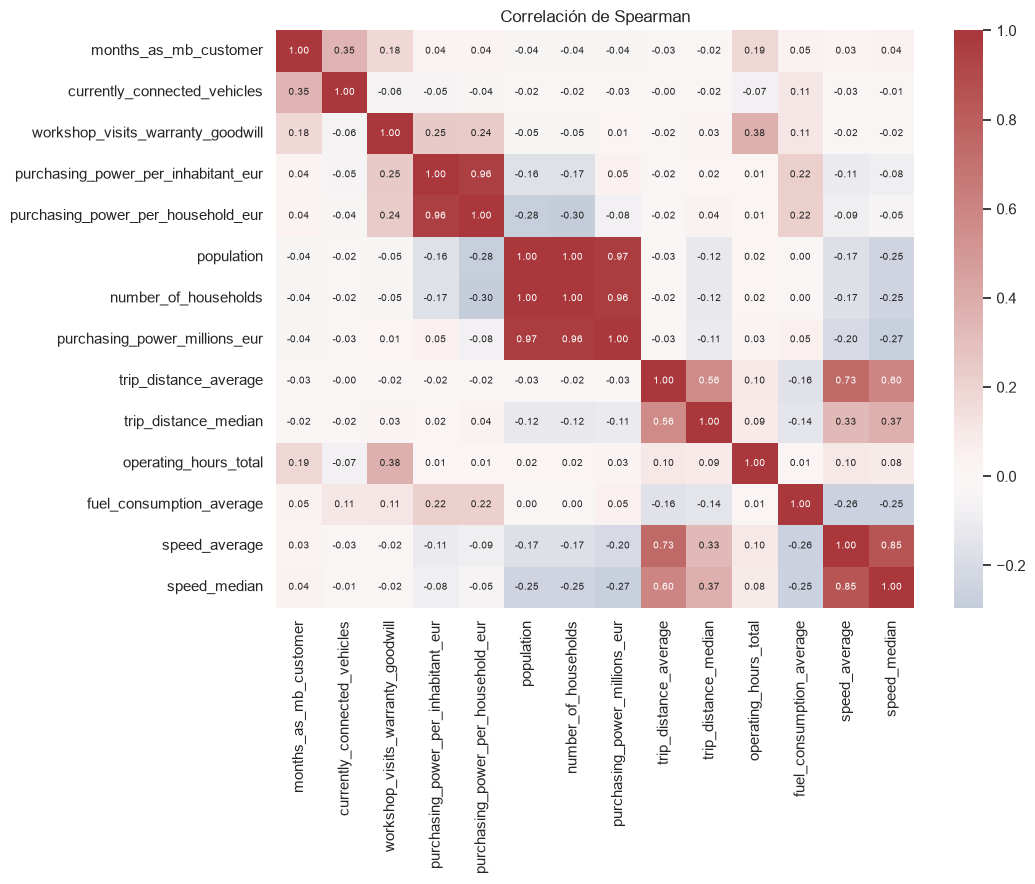

ρ
population                          number_of_households               1.00
                                    purchasing_power_millions_eur      0.97
number_of_households                purchasing_power_millions_eur      0.96
purchasing_power_per_inhabitant_eur purchasing_power_per_household_eur 0.96
speed_average                       speed_median                       0.85

In [15]:
corr_cols = ["months_as_mb_customer", "currently_connected_vehicles", "workshop_visits_warranty_goodwill",
             "purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur", "population",
             "number_of_households", "purchasing_power_millions_eur", "trip_distance_average",
             "trip_distance_median", "operating_hours_total", "fuel_consumption_average",
             "speed_average", "speed_median"]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlación de Spearman")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.8].sort_values(ascending=False).to_frame("ρ")

In [16]:
# purchasing_power_millions_eur es una variable calculada
rebuilt = df["purchasing_power_per_household_eur"] * df["number_of_households"] / 1e6
rel_err = ((rebuilt - df["purchasing_power_millions_eur"]).abs() / df["purchasing_power_millions_eur"])
print("Error relativo mediano (per_household × households vs millions):", f"{rel_err.median():.2e}")

# role_type se deriva de role
pd.crosstab(df["role"], df["role_type"])

Error relativo mediano (per_household × households vs millions): 5.85e-07


role_type,B2B,B2C
role,,
DRIVER,5521,0
LEGACY,0,11314
OWNER,0,264418
TEMP_USER,0,3966
USER,0,17631


**Interpretación**

- `engine_concept` y `fuel_type` son **coherentes** entre sí (ELECTRIC↔ELECTRIC, `*,ELECTRIC`↔PLUGIN_HYBRID), pero los nulos coinciden: en las 134.390 filas sin `engine_concept` tampoco hay `fuel_type`, por lo que no permiten imputarse entre sí.
- `trip_distance_mode` y `speed_mode` mezclan valores con **listas de intervalos** en texto: no son utilizables y ya disponemos de la media.
- Hay outliers físicamente dudosos (velocidad media > 150 km/h, consumo > 25 l/100 km) y contadores con colas extremas. Al ser muy pocos y de origen incierto, se propone **winsorizar (p1–p99)** y aplicar **log** a contadores y horas en lugar de eliminar filas.
- `population = 0` en zonas con datos socioeconómicos es incoherente → se trata como nulo.
- Más de un millar de clientes tienen más de 10 vehículos y la mayoría figuran como B2C: probablemente flotas o concesionarios mal etiquetados → se mantienen (Q10): el log del nº de vehículos y el recorte p1–p99 del Reto 2 limitan su peso en K-Means.
- `currently_connected_vehicles` coincide exactamente con el número de vehículos actuales: la variable es fiable.
- **Redundancias:** `population`≈`number_of_households`, `purchasing_power_millions_eur` es literalmente `per_household × households`, las dos variables de poder adquisitivo están casi perfectamente correlacionadas y `speed_median`≈`speed_average`. `role_type = B2B` equivale a `role = DRIVER`. La elección de cuál conservar se hace en el Reto 2.

## 5. Distribuciones de variables clave

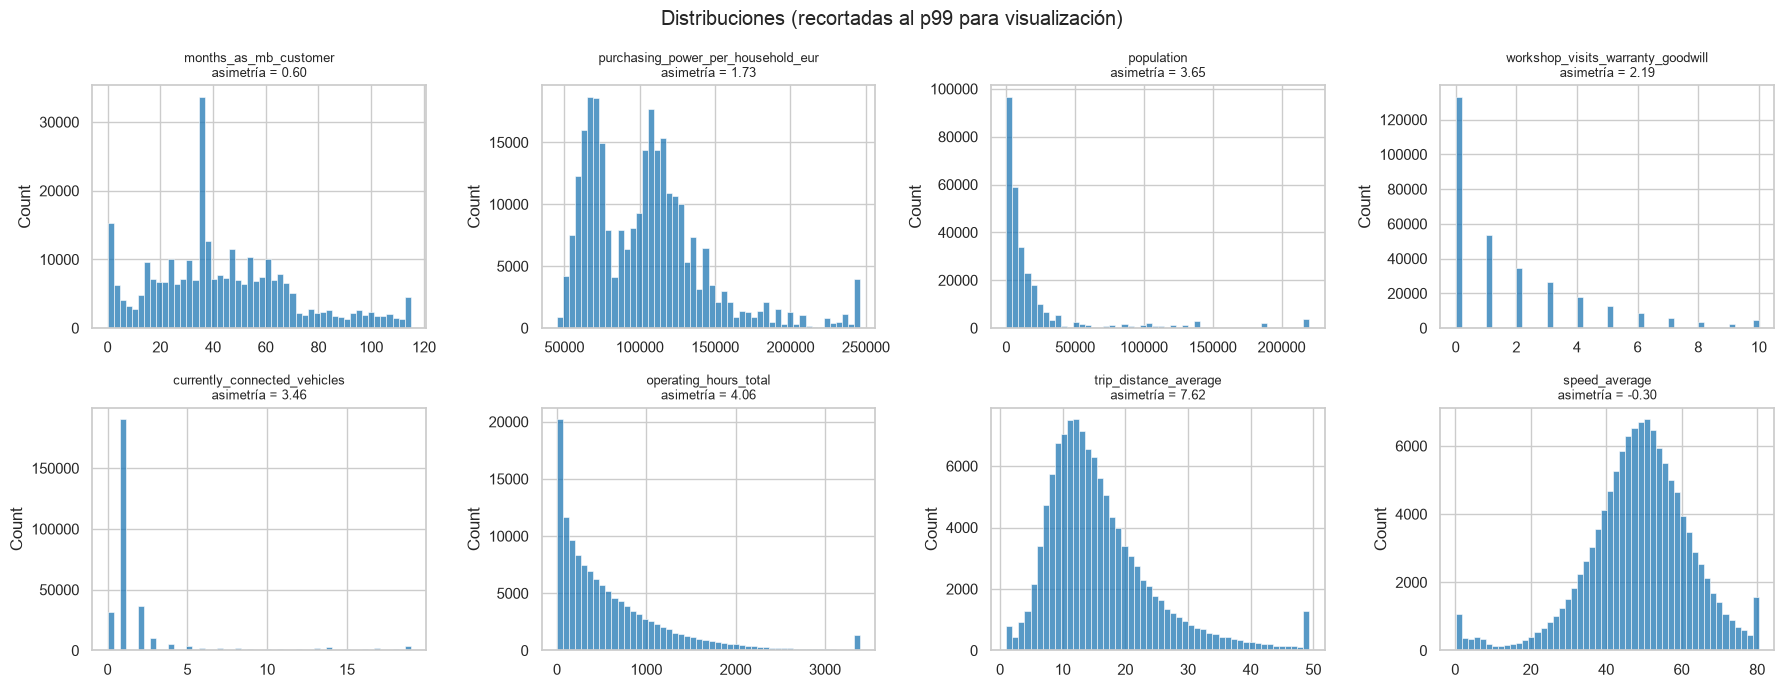

In [17]:
dist_cols = ["months_as_mb_customer", "purchasing_power_per_household_eur", "population",
             "workshop_visits_warranty_goodwill", "currently_connected_vehicles",
             "operating_hours_total", "trip_distance_average", "speed_average"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, dist_cols):
    s = df[c].dropna()
    sns.histplot(s.clip(upper=s.quantile(.99)), bins=50, ax=ax, color="tab:blue")
    ax.set_title(f"{c}\nasimetría = {s.skew():.2f}", fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Distribuciones (recortadas al p99 para visualización)")
plt.tight_layout()
plt.show()

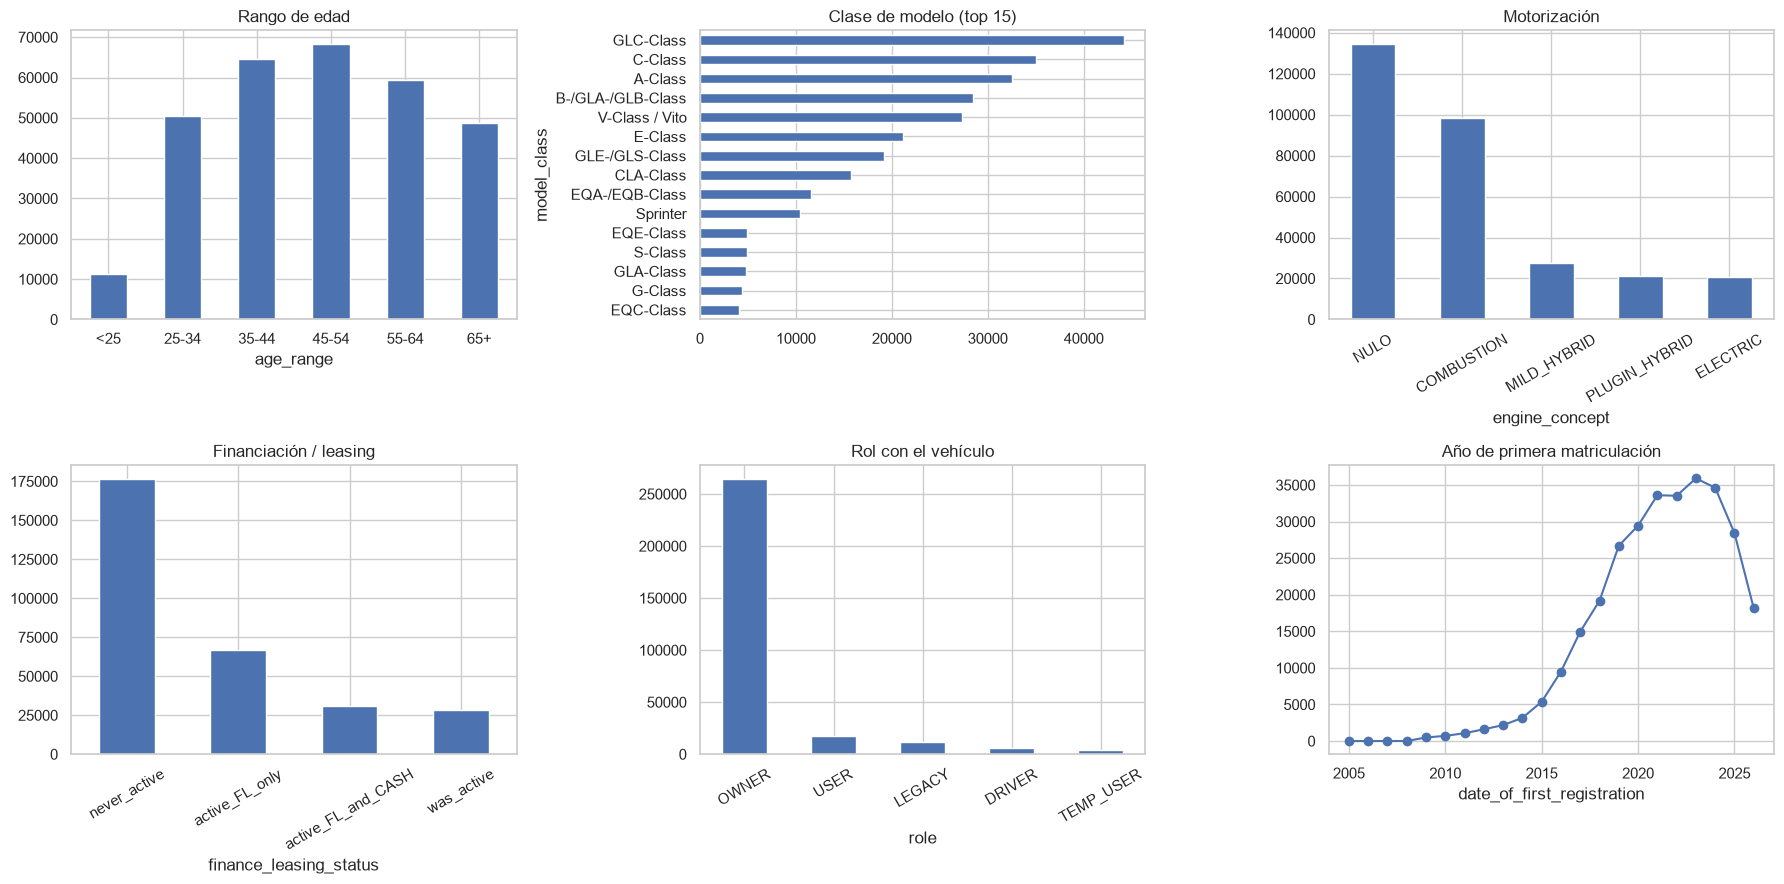

In [18]:
age_order = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
df["age_range"].value_counts().reindex(age_order).plot.bar(ax=axes[0, 0], title="Rango de edad", rot=0)
df["model_class"].value_counts().head(15).plot.barh(ax=axes[0, 1], title="Clase de modelo (top 15)").invert_yaxis()
df["engine_concept"].fillna("NULO").value_counts().plot.bar(ax=axes[0, 2], title="Motorización", rot=30)
df["finance_leasing_status"].value_counts().plot.bar(ax=axes[1, 0], title="Financiación / leasing", rot=30)
df["role"].value_counts().plot.bar(ax=axes[1, 1], title="Rol con el vehículo", rot=30)
reg.dt.year.value_counts().sort_index().loc[2005:].plot(ax=axes[1, 2], marker="o", title="Año de primera matriculación")
plt.tight_layout()
plt.show()

In [19]:
# Visión a nivel cliente (una fila por cliente)
clients = g.agg(
    age_range=("age_range", "first"),
    gender=("gender_derived", "first"),
    country=("country_code", "first"),
    months_as_mb_customer=("months_as_mb_customer", "first"),
    finance=("finance_leasing_status", "first"),
    n_vehicles=("vehicle_id", "nunique"),
    n_current=("is_current_vehicle", "sum"),
    is_b2b=("role_type", lambda s: (s == "B2B").any()),
    phone=("consent_phone_communication_channel", "first"),
    epost=("consent_epost_communication_channel", "first"),
    post=("consent_post_communication_channel", "first"),
    pp_household=("purchasing_power_per_household_eur", "first"),
)
print(f"Clientes: {len(clients):,}")
print("Vehículos por cliente — mediana:", clients["n_vehicles"].median(), "| % con 1 solo vehículo:",
      round((clients["n_vehicles"] == 1).mean() * 100, 1))
print("% clientes sin vehículo actual:", round((clients["n_current"] == 0).mean() * 100, 1))
print("% clientes con alguna relación B2B:", round(clients["is_b2b"].mean() * 100, 1))
print("Antigüedad mediana (meses):", clients["months_as_mb_customer"].median())
print("Poder adquisitivo por hogar, mediana (€):", f"{clients['pp_household'].median():,.0f}")
print("% consentimiento teléfono / ePost / correo:",
      [round(clients[c].mean() * 100, 1) for c in ["phone", "epost", "post"]])
pd.concat({
    "género": clients["gender"].fillna("unknown").value_counts(normalize=True),
    "país": clients["country"].value_counts(normalize=True),
    "edad": clients["age_range"].value_counts(normalize=True).reindex(age_order),
    "financiación": clients["finance"].value_counts(normalize=True),
}).mul(100).round(1).rename("% clientes").to_frame()

Clientes: 173,456
Vehículos por cliente — mediana: 1.0 | % con 1 solo vehículo: 73.3
% clientes sin vehículo actual: 10.4
% clientes con alguna relación B2B: 0.6
Antigüedad mediana (meses): 36.0
Poder adquisitivo por hogar, mediana (€): 103,738
% consentimiento teléfono / ePost / correo: [np.float64(86.1), np.float64(98.3), np.float64(85.2)]


% clientes
género       male                     65.00
             female                   18.10
             unknown                  16.90
país         CH                       66.20
             AT                       33.80
edad         <25                       4.70
             25-34                    15.50
             35-44                    18.90
             45-54                    21.00
             55-64                    19.60
             65+                      20.20
financiación never_active             70.60
             active_FL_only           23.70
             was_active                3.30
             active_FL_and_CASH        2.40

In [20]:
# Dos patrones llamativos de los histogramas
first = df.drop_duplicates("client_id")
months_vc = first["months_as_mb_customer"].value_counts()
print("Valores más frecuentes de months_as_mb_customer (clientes):", months_vc.head(4).to_dict())
print(f"% clientes con exactamente 36 meses: {months_vc[36] / len(first) * 100:.1f} %")
first.groupby("country_code")["purchasing_power_per_household_eur"].median().to_frame("poder adquisitivo/hogar mediano (€)")

Valores más frecuentes de months_as_mb_customer (clientes): {36.0: 21179, 0.0: 7254, 18.0: 3262, 1.0: 3002}
% clientes con exactamente 36 meses: 12.2 %


,poder adquisitivo/hogar mediano (€)
country_code,
AT,"66,938.25"
CH,"116,082.37"


**Interpretación**

- **Pico en 36 meses:** el 12 % de los clientes tiene exactamente 36 meses de antigüedad (6 veces más que el siguiente valor). Parece un valor por defecto o una fecha de corte del sistema (p. ej. inicio del registro de conexiones), no una antigüedad real. Propuesta: flag `months_is_36` y tratarlo con cautela al interpretar segmentos.
- **Poder adquisitivo bimodal:** cada moda corresponde a un país (Suiza ≈ 116.000 €/hogar frente a Austria ≈ 67.000 €). Comparar clientes de distintos países en euros absolutos mezcla el efecto país; se propone imputar por país y valorar normalizar dentro de cada país.
- Las variables de conteo y uso (`workshop_visits`, `currently_connected_vehicles`, `operating_hours_total`, `population`) presentan **fuerte asimetría positiva** → en el Reto 2 se transformarán con logaritmo antes de escalar, ya que K-Means es sensible a la escala y a los extremos.
- `months_as_mb_customer` y `speed_average` tienen distribuciones más simétricas: basta con escalado estándar.
- La base de clientes está concentrada en edades medias-altas, con predominio de SUV (GLC, GLE) y compactos (A, C, B/GLA).
- Las matriculaciones crecen hasta 2023; el año en curso aparece incompleto.

## 6. Exclusión de identificadores y metadatos

Aquí solo se eliminan las columnas que **no aportan valor analítico**. La selección de features por criterio de negocio (y la resolución de redundancias) se hace en el Reto 2, apoyándose en la evidencia de este notebook.

| Columna | Motivo |
|---|---|
| índice sin nombre | Artefacto de exportación (ya usado como `index_col`) |
| `client_id` | Identificador hash; se conserva **solo** como clave de agregación |
| `vehicle_id` | Identificador hash; solo sirve para contar vehículos |
| `zipcode` | Identificador geográfico; su información ya está en las variables socioeconómicas |
| `trip_distance_all_counter`, `speed_all_counter` | Metadatos de cálculo de las métricas (nº de mediciones), no comportamiento del cliente |
| `trip_distance_mode`, `speed_mode` | Texto con listas de intervalos, inutilizable (sección 4.2) |

In [21]:
drop_cols = ["vehicle_id", "zipcode", "trip_distance_all_counter", "speed_all_counter",
             "trip_distance_mode", "speed_mode"]
df_eda = df.drop(columns=drop_cols)
print("Columnas antes:", df.shape[1], "→ después:", df_eda.shape[1])
print("Se mantiene client_id como clave de agregación para el Reto 2")

Columnas antes: 38 → después: 32
Se mantiene client_id como clave de agregación para el Reto 2


## 7. Resumen y conclusiones

### Principales características de los clientes

Cifras a nivel **cliente** (173.456 clientes), no a nivel fila:

- **Mercado:** solo Suiza (66 %) y Austria (34 %).
- **Demografía:** 65 % hombres, 18 % mujeres y 17 % sin género inferido. Base madura: el 61 % tiene 45 años o más y solo el 5 % es menor de 25.
- **Tipo de cliente:** prácticamente todo particular (B2B < 1 % de los clientes). El 87 % de las relaciones cliente–vehículo son de propietario.
- **Vehículos:** el 73 % de los clientes tiene un único vehículo (mediana 1), pero existen ~1.700 cuentas con más de 10 vehículos que parecen flotas. Predominan SUV (GLC, GLE/GLS, GLA/GLB) y compactos/medios (A, C, CLA); un 14 % de las filas son vehículos comerciales (`product_group = T`: V-Class/Vito, Sprinter…). Con dato de motorización, la combustión domina, pero los electrificados (mild hybrid, PHEV y eléctricos) ya suponen ~41 %.
- **Relación con la marca:** antigüedad mediana de 36 meses; el 10 % de los clientes no tiene ningún vehículo actual (antiguos clientes). El 71 % nunca ha usado financiación o leasing y el 24 % tiene un leasing financiero activo.
- **Canales:** ePost autorizado por el 98 %; teléfono (86 %) y correo postal (85 %).
- **Zona:** poder adquisitivo por hogar mediano ≈ 104.000 €, con una brecha fuerte entre Suiza y Austria.
- **Conectividad:** solo ~48 % de las filas tiene algún dato de telemetría; entre ellos, trayectos medios de ~16 km y velocidad media de ~49 km/h.

### Problemas de calidad encontrados y tratamiento

| # | Problema | Evidencia | Tratamiento |
|---|---|---|---|
| Q0 | Fichero descargado truncado | Faltaban 17.925 filas y una línea empalmada | Re-descarga y verificación (SHA-256, índice continuo). **Resuelto** |
| Q1 | `zipcode` con tipos mezclados | pandas mezclaba `int` y `str` | Lectura con `dtype={"zipcode": str}`. **Resuelto** |
| Q2 | Granularidad cliente–vehículo | 302.850 filas / 173.456 clientes | Agregar a una fila por cliente (Reto 2) |
| Q3 | Telemetría ausente (~60 %) | Nulos en bloque, más frecuentes en vehículos no actuales: no aleatorios | Flag `has_telemetry` + agregación; no imputar a ciegas |
| Q4 | `engine_concept` (44 %) y `fuel_type` (59 %) nulos | Coherentes entre sí, pero nulos en las mismas filas (sección 4.1) | Completar desde `vehicle_type` en el Reto 2 |
| Q5 | `gender_derived` nulo (11 %) e inferido | Diccionario de datos | Categoría `unknown`; solo para perfilado |
| Q6 | Socioeconómicas nulas (6 %) y `population = 0` (73) | — | Ceros a nulo; mediana por país |
| Q7 | `*_mode` con listas de intervalos en texto | 7.049 y 1.223 filas | Excluidas |
| Q8 | Outliers | Velocidad media > 150 km/h (26), consumo > 25 l (604), contadores extremos | Winsorizar p1–p99 y log (Reto 2) |
| Q9 | Redundancias | ρ ≥ 0,85 en 5 pares; `pp_millions` es calculada; `role_type` ⇔ `role` | Conservar una por grupo (Reto 2) |
| Q10 | Posibles flotas como B2C | ~1.700 clientes con > 10 vehículos | Se mantienen: `log` del nº de vehículos y recorte p1–p99 limitan su peso en K-Means (Reto 2) |
| Q11 | Pico de antigüedad en 36 meses | 12 % de los clientes | Se mantiene como valor válido; se tendrá en cuenta al interpretar los segmentos (Reto 4) |
| Q12 | Fecha de matriculación (1,4 %) y `model_class` (1,1 %) nulas | — | Imputación por `model_series` |
| Q13 | Identificadores y metadatos | `client_id`, `vehicle_id`, `zipcode`, contadores | Excluidos (sección 6) |

### Decisiones que pasan al Reto 2

1. Agregar a nivel cliente (vehículos actuales, % enchufables, segmento principal, `is_b2b`, `has_telemetry`).
2. Crear la feature derivada `vehicle_age_years` desde `date_of_first_registration`.
3. Seleccionar features por criterio de negocio apoyándose en la evidencia de este notebook (redundancias, cardinalidad, baja varianza de `consent_epost`).
4. Telemetría: entra en el modelo solo como `has_telemetry`; sus métricas se reservan para perfilar los segmentos.

La implementación está en `02_feature_engineering.ipynb`.